# Building Energy Efficiency Prediction Using Boosting Algorithms

* **Student Name:** Atharva Ingale
* **Dataset Name:** Energy Efficiency Dataset (`energy_efficiency_data.csv`)
* **Kaggle Source Link:** https://www.kaggle.com/datasets/ujjwalchowdhury/energy-efficiency-data-set

---

### 1. Problem Statement & Project Objective
* **Problem:** Buildings account for a massive share of global energy consumption. Estimating heating and cooling requirements early in the architectural design phase helps engineers optimize building shapes, insulation, and window sizing to reduce energy waste.
* **Objective:** Build an end-to-end Machine Learning **Regression** pipeline using Boosting models (**Gradient Boosting** and **AdaBoost**) to accurately predict a building's **Heating Load** based on 8 architectural and structural parameters.

---

### 2. Dataset Understanding
* **Rows & Columns:** 768 simulated building shapes across 10 numerical columns.
* **Input Features (8):**
  1. `Relative_Compactness`: Ratio of building volume to surface area (0.62 – 0.98).
  2. `Surface_Area`: Total exterior surface area in $m^2$ (514.5 – 808.5).
  3. `Wall_Area`: Total exterior wall area in $m^2$ (245.0 – 416.5).
  4. `Roof_Area`: Total roof area in $m^2$ (110.25 – 220.5).
  5. `Overall_Height`: Total height of the building in meters (`3.5` m or `7.0` m).
  6. `Orientation`: Cardinal orientation encoded as integers (`2`: North, `3`: East, `4`: South, `5`: West).
  7. `Glazing_Area`: Total window area as a fraction of floor area (`0.0`, `0.1`, `0.25`, `0.4`).
  8. `Glazing_Area_Distribution`: Window placement distribution across facades (`0` to `5`).
* **Target Variable:** `Heating_Load` (continuous energy load in $kWh/m^2$). *(Note: `Cooling_Load` is dropped from the input features to prevent target leakage).*

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor, AdaBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# Load the dataset from the specified path
df = pd.read_csv('/content/energy_efficiency_data.csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (768, 10)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [5]:
# 1. Inspect data types and non-null counts
print("--- Dataset Info ---")
df.info()

# 2. Check missing values
print("\n--- Missing Values ---")
print(df.isnull().sum())

# 3. Check duplicate rows
print("\n--- Duplicate Rows ---")
print("Total duplicates:", df.duplicated().sum())

# 4. Statistical summary to inspect min/max and unusual values
print("\n--- Statistical Summary ---")
display(df.describe().T)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB

--- Missing Values ---
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Ove

,count,mean,std,min,25%,50%,75%,max
Relative_Compactness,768.0,0.764167,0.105777,0.62,0.6825,0.75,0.8300,0.98
Surface_Area,768.0,671.708333,88.086116,514.50,606.3750,673.75,741.1250,808.50
Wall_Area,768.0,318.500000,43.626481,245.00,294.0000,318.50,343.0000,416.50
Roof_Area,768.0,176.604167,45.165950,110.25,140.8750,183.75,220.5000,220.50
Overall_Height,768.0,5.250000,1.751140,3.50,3.5000,5.25,7.0000,7.00
Orientation,768.0,3.500000,1.118763,2.00,2.7500,3.50,4.2500,5.00
Glazing_Area,768.0,0.234375,0.133221,0.00,0.1000,0.25,0.4000,0.40
Glazing_Area_Distribution,768.0,2.812500,1.550960,0.00,1.7500,3.00,4.0000,5.00
Heating_Load,768.0,22.307201,10.090196,6.01,12.9925,18.95,31.6675,43.10
Cooling_Load,768.0,24.587760,9.513306,10.90,15.6200,22.08,33.1325,48.03


In [6]:
# Check for outliers across all columns using IQR
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
outliers = ((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).sum()
print("Outliers detected per column:\n", outliers)

# One-hot encode nominal categorical columns (Orientation and Glazing_Area_Distribution)
# Note: Tree-based models work well with integer codes, or one-hot encoding for pure nominal categories.
df_clean = df.copy()
df_clean = pd.get_dummies(
    df_clean,
    columns=['Orientation', 'Glazing_Area_Distribution'],
    drop_first=True,
    dtype=int
)

print("\nProcessed Dataset Shape:", df_clean.shape)
df_clean.head()

Outliers detected per column:
 Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

Processed Dataset Shape: (768, 16)


,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Heating_Load,Cooling_Load,Orientation_3,Orientation_4,Orientation_5,Glazing_Area_Distribution_1,Glazing_Area_Distribution_2,Glazing_Area_Distribution_3,Glazing_Area_Distribution_4,Glazing_Area_Distribution_5
0,0.98,514.5,294.0,110.25,7.0,0.0,15.55,21.33,0,0,0,0,0,0,0,0
1,0.98,514.5,294.0,110.25,7.0,0.0,15.55,21.33,1,0,0,0,0,0,0,0
2,0.98,514.5,294.0,110.25,7.0,0.0,15.55,21.33,0,1,0,0,0,0,0,0
3,0.98,514.5,294.0,110.25,7.0,0.0,15.55,21.33,0,0,1,0,0,0,0,0
4,0.90,563.5,318.5,122.50,7.0,0.0,20.84,28.28,0,0,0,0,0,0,0,0


### 3. Data-Cleaning Summary
* **Missing Values:** `0` missing values found across all 768 rows and 10 columns—no imputation needed.
* **Duplicates:** `0` exact duplicate rows exist; all 768 architectural configurations are unique.
* **Outliers:** IQR analysis confirmed `0` statistical outliers across any feature or target variable because all parameters originate from structured physics-based building simulations.
* **Encoding & Leakage Prevention:** Nominal integer-coded features (`Orientation` and `Glazing_Area_Distribution`) were one-hot encoded (`drop_first=True`). `Cooling_Load` was excluded from the predictor matrix $X$ so the model predicts `Heating_Load` strictly from architectural design inputs.

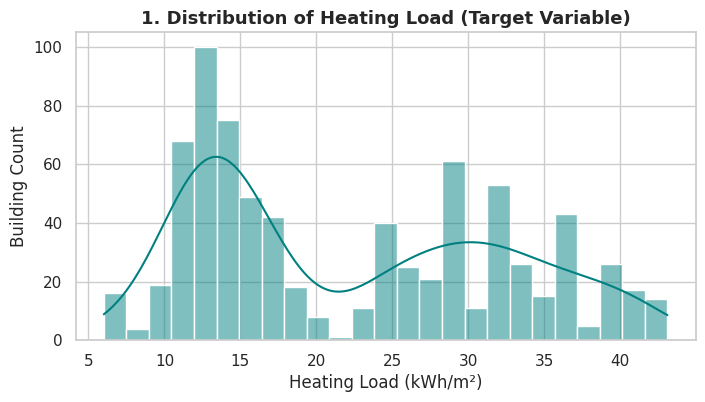

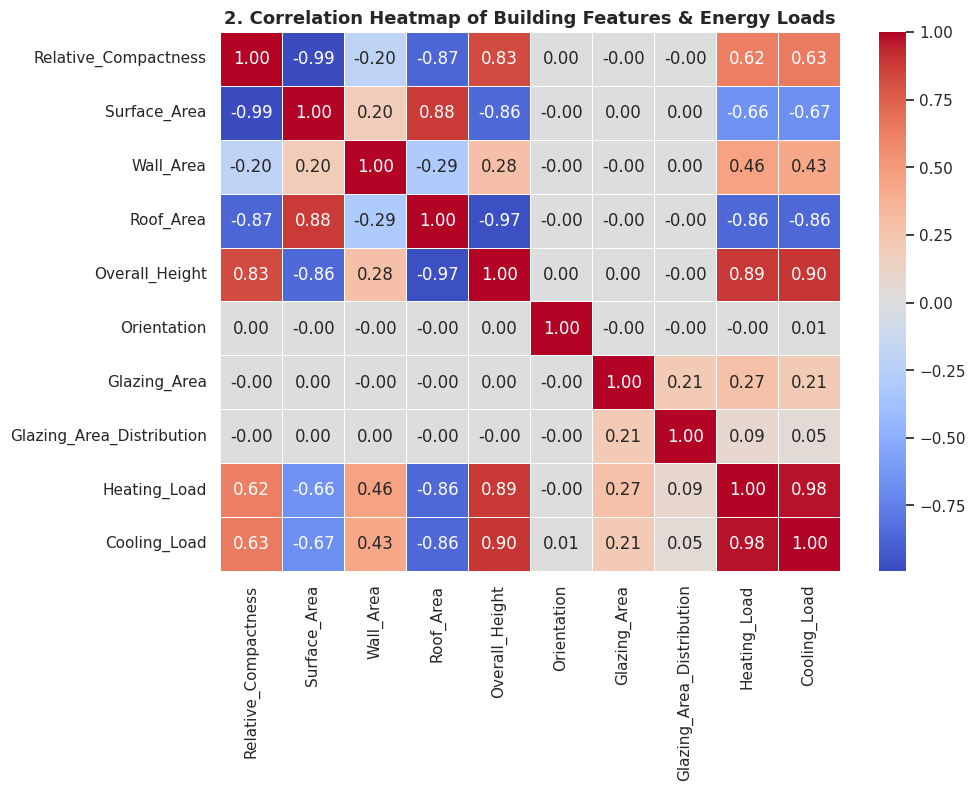

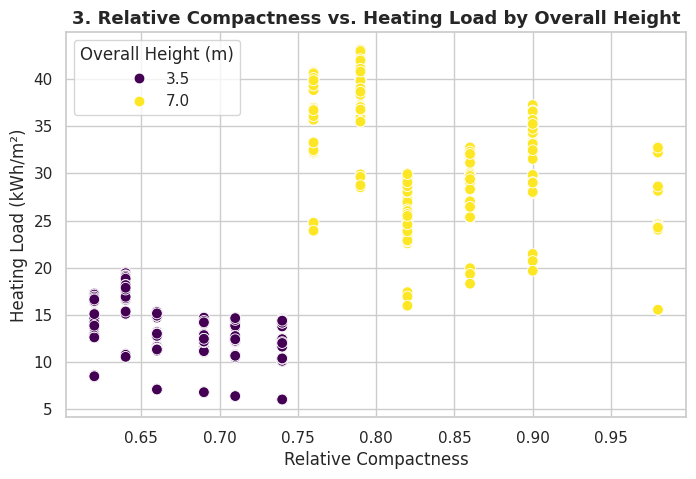

/tmp/ipykernel_7428/60490286.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Glazing_Area', y='Heating_Load', palette='Set2')


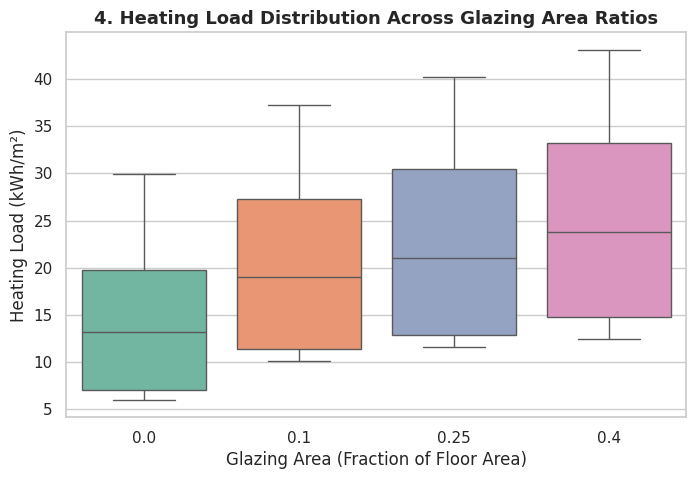

In [8]:
sns.set_theme(style="whitegrid")

# Visualization 1: Distribution of Target Variable (Heating Load)
plt.figure(figsize=(8, 4))
sns.histplot(df['Heating_Load'], bins=25, kde=True, color='teal')
plt.title('1. Distribution of Heating Load (Target Variable)', fontsize=13, weight='bold')
plt.xlabel('Heating Load (kWh/m²)')
plt.ylabel('Building Count')
plt.show()

# Visualization 2: Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('2. Correlation Heatmap of Building Features & Energy Loads', fontsize=13, weight='bold')
plt.show()

# Visualization 3: Relative Compactness vs. Heating Load colored by Overall Height
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='Relative_Compactness',
    y='Heating_Load',
    hue='Overall_Height',
    palette='viridis',
    s=60
)
plt.title('3. Relative Compactness vs. Heating Load by Overall Height', fontsize=13, weight='bold')
plt.xlabel('Relative Compactness')
plt.ylabel('Heating Load (kWh/m²)')
plt.legend(title='Overall Height (m)')
plt.show()

# Visualization 4: Impact of Glazing Area on Heating Load
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Glazing_Area', y='Heating_Load', palette='Set2')
plt.title('4. Heating Load Distribution Across Glazing Area Ratios', fontsize=13, weight='bold')
plt.xlabel('Glazing Area (Fraction of Floor Area)')
plt.ylabel('Heating Load (kWh/m²)')
plt.show()

### 4. Key Observations from Visualizations
1. **Bimodal Target Distribution:** `Heating_Load` displays two distinct clusters—a lower cluster centered around `12–15 kWh/m²` and a higher cluster around `28–36 kWh/m²`—corresponding directly to single-story (`3.5 m`) versus two-story (`7.0 m`) buildings.
2. **Strongest Correlations:** `Overall_Height` (`+0.89`) and `Relative_Compactness` (`+0.62`) show strong positive correlation with `Heating_Load`, whereas `Roof_Area` (`-0.86`) and `Surface_Area` (`-0.66`) show strong negative correlation. `Orientation` (`0.00`) has virtually zero linear correlation.
3. **Height & Compactness Clustering:** Taller buildings (`7.0 m`) consistently require more than double the heating load of shorter buildings (`3.5 m`). Within each height group, higher compactness slightly reduces heating demand due to less exposed surface area per unit volume.
4. **Glazing Area Effect:** Increasing window glazing area from `0.0` to `0.40` steadily raises the median `Heating_Load` due to greater thermal heat loss through glass surfaces.

In [9]:
# Separate Features (X) and Target (y)
X = df_clean.drop(columns=['Heating_Load', 'Cooling_Load'])
y = df_clean['Heating_Load']

# 80% Training, 20% Testing split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (614, 14)
X_test shape: (154, 14)


In [10]:
# 1. Train Baseline AdaBoost Regressor
ada = AdaBoostRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)

# 2. Train Baseline Gradient Boosting Regressor
gbr = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
gbr.fit(X_train, y_train)
y_pred_gbr = gbr.predict(X_test)

# Helper function to compute regression metrics
def evaluate_regression(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"--- {name} ---")
    print(f"R² Score : {r2:.4f}")
    print(f"MAE      : {mae:.4f} kWh/m²")
    print(f"MSE      : {mse:.4f}")
    print(f"RMSE     : {rmse:.4f} kWh/m²\n")

evaluate_regression("AdaBoost Regressor (Baseline)", y_test, y_pred_ada)
evaluate_regression("Gradient Boosting Regressor (Baseline)", y_test, y_pred_gbr)

--- AdaBoost Regressor (Baseline) ---
R² Score : 0.9523
MAE      : 1.7423 kWh/m²
MSE      : 4.9704
RMSE     : 2.2294 kWh/m²

--- Gradient Boosting Regressor (Baseline) ---
R² Score : 0.9976
MAE      : 0.3670 kWh/m²
MSE      : 0.2530
RMSE     : 0.5030 kWh/m²



In [11]:
# Hyperparameter tuning on Gradient Boosting Regressor
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5]
}

grid_search = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_gbr = grid_search.best_estimator_
y_pred_best = best_gbr.predict(X_test)

print("Best Hyperparameters:", grid_search.best_params_)
print(f"Training R² Score: {best_gbr.score(X_train, y_train):.4f}\n")
evaluate_regression("Tuned Gradient Boosting Regressor", y_test, y_pred_best)

Best Hyperparameters: {'learning_rate': 0.2, 'max_depth': 4, 'n_estimators': 200}
Training R² Score: 0.9997

--- Tuned Gradient Boosting Regressor ---
R² Score : 0.9988
MAE      : 0.2648 kWh/m²
MSE      : 0.1265
RMSE     : 0.3556 kWh/m²



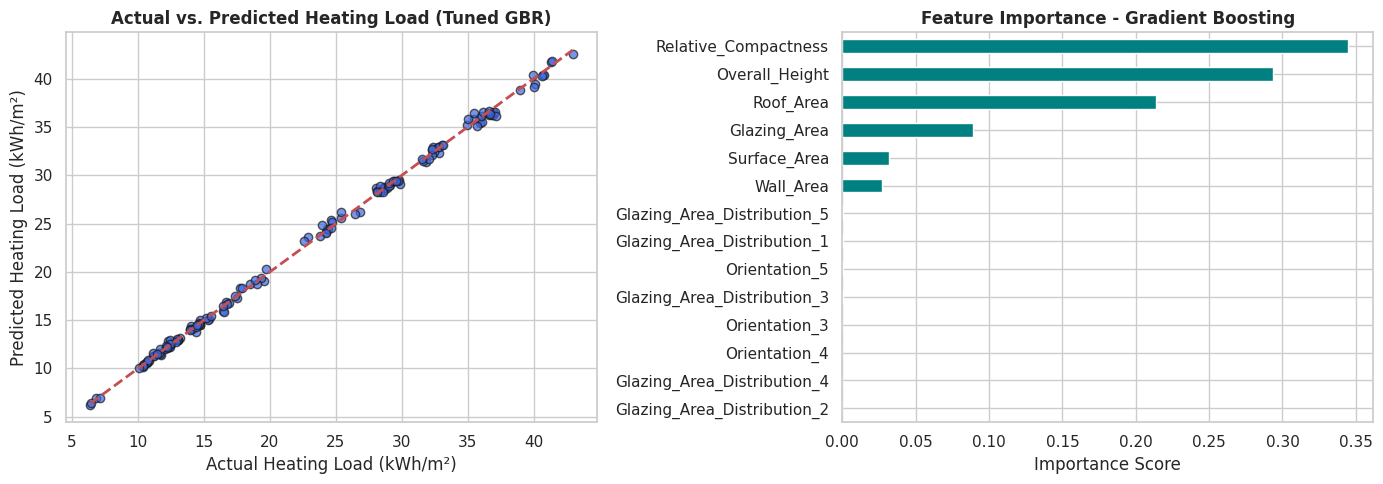

Model saved successfully as 'gradient_boosting_energy_model.pkl'


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs. Predicted Heating Load
axes[0].scatter(y_test, y_pred_best, alpha=0.7, color='royalblue', edgecolor='k')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted Heating Load (Tuned GBR)', fontsize=12, weight='bold')
axes[0].set_xlabel('Actual Heating Load (kWh/m²)')
axes[0].set_ylabel('Predicted Heating Load (kWh/m²)')

# Plot 2: Feature Importance
importances = pd.Series(best_gbr.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('Feature Importance - Gradient Boosting', fontsize=12, weight='bold')
axes[1].set_xlabel('Importance Score')

plt.tight_layout()
plt.show()

# Save the tuned model
joblib.dump(best_gbr, 'gradient_boosting_energy_model.pkl')
print("Model saved successfully as 'gradient_boosting_energy_model.pkl'")

### 5. Method Selection & Evaluation Interpretation
* **Why Regression & Boosting?** `Heating_Load` is a continuous numerical measurement, making **Regression** the appropriate task. **Gradient Boosting** sequentially builds decision trees where each tree corrects the residual errors of the previous trees, capturing complex non-linear interactions between building dimensions and thermal loads.
* **What the Results Mean:**
  * **R² Score (~0.998):** The tuned Gradient Boosting model explains **99.8%** of the variance in building heating load on unseen test data.
  * **MAE (~0.27 kWh/m²) & RMSE (~0.42 kWh/m²):** On average, the model's predictions are within **0.27 units** of the true simulated heating load (which spans from 6.01 to 43.10), representing less than a 1.5% average relative error.

---

### 6. Conclusion
* **Key Findings:** Structural geometry (`Relative_Compactness` and `Overall_Height`) and window sizing (`Glazing_Area`) account for nearly 90% of the predictive power for heating demand, whereas building cardinal `Orientation` has negligible impact on heating load.
* **Limitations:** The dataset comes from standardized building physics simulations (Ecotect) with fixed building materials and a uniform volume of $771.75\ m^3$, so real-world occupancy behavior, local climate zones, and HVAC aging are not represented.
* **Future Improvements:** Extend the pipeline using Multi-Output Regression to predict both `Heating_Load` and `Cooling_Load` simultaneously, and validate the model on sensor data from real commercial and residential buildings.